# 03 Simple giveaways and baselines

Before any neural network: **what separates human and AI reviews without deep learning?**
If a single simple feature (length, final punctuation…) already separates the classes, that is a finding, and every
later model has to clearly beat it to show it learned more than that.

1. Simple features per review, compared for human, Mistral (train) and Qwen (held out)
2. The most distinctive words of each class
3. Baselines, all trained on `train` only and scored on `val`, `test`, `heldout_qwen` and `reserve_human`:
   dummy, length only, simple features, TF-IDF + logistic regression

Runs on CPU (Colab or locally). Results without review text are saved to `results/03_baselines/`.

## 1. Load the dataset

In [ ]:
import re, json, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Colab: the team Drive. Locally: data/final/dataset_v1.csv in the repository (git-ignored).
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = Path("/content/drive/MyDrive/TA2/data/final/dataset_v1.csv")
    RESULTS = Path("/content/drive/MyDrive/TA2/results/03_baselines")
except ImportError:
    DATA = Path("../data/final/dataset_v1.csv")
    RESULTS = Path("../results/03_baselines")
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42

df = pd.read_csv(DATA)
df["text"] = df.text.astype(str)
print(df.shape)
df.groupby(["split", "generator"]).size().unstack(fill_value=0)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(39292, 14)


generator,human,mistral,qwen
split,,,
heldout_qwen,2758,0,2758
reserve_human,16090,0,0
test,1327,1327,0
train,6190,6190,0
val,1326,1326,0


## 2. Simple features

Each feature is something a reader could notice without any model. Groups compared:
**human** (train), **mistral** (train) and **qwen** (`heldout_qwen`, the AI side only).

In [ ]:
EMOJI = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B50\u2764]")
NO_APOSTROPHE = re.compile(r"\b(dont|cant|wont|didnt|doesnt|isnt|im|ive|youre|thats|its a)\b", re.I)  # "its a" ~ "it's a"
LOWER_I = re.compile(r"(?:^|\s)i(?:\s|$|[,.!?])")
# Words that are typical for LLM marketing-style text (chosen before looking at model results; checked below)
AI_WORDS = ["immersive", "captivating", "masterpiece", "stunning", "breathtaking", "engaging", "unforgettable",
            "rollercoaster", "testament", "delightful", "seamless", "hooked", "enthusiasts", "gem", "realm"]
AI_WORD_RE = re.compile(r"\b(" + "|".join(AI_WORDS) + r")\b", re.I)

def features(text):
    words = re.findall(r"[A-Za-z']+", text)
    letters = [c for c in text if c.isalpha()]
    stripped = text.strip()
    return {
        "words": len(text.split()),
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
        "ends_with_punct": stripped[-1:] in list(".!?)…") or bool(EMOJI.search(stripped[-1:])),
        "exclamations": text.count("!"),
        "questions": text.count("?"),
        "ellipsis": "..." in text or "…" in text,
        "uppercase_share": sum(c.isupper() for c in letters) / len(letters) if letters else 0,
        "starts_lowercase": stripped[:1].islower(),
        "lowercase_i": bool(LOWER_I.search(text)),
        "no_apostrophe": bool(NO_APOSTROPHE.search(text)),
        "emoji": bool(EMOJI.search(text)),
        "hashtag": "#" in text,
        "newlines": "\n" in text,
        "ai_words": len(AI_WORD_RE.findall(text)),
        "type_token_ratio": len(set(w.lower() for w in words)) / len(words) if words else 0,
    }

feat = pd.DataFrame([features(t) for t in df.text], index=df.index)
df = df.join(feat)
FEATURES = list(feat.columns)

groups = {
    "human (train)": df[(df.split == "train") & (df.label == 0)],
    "mistral (train)": df[(df.split == "train") & (df.label == 1)],
    "qwen (held out)": df[(df.split == "heldout_qwen") & (df.label == 1)],
}
compare = pd.DataFrame({name: g[FEATURES].mean() for name, g in groups.items()}).round(3)
compare.to_csv(RESULTS / "feature_means.csv")
compare

,human (train),mistral (train),qwen (held out)
words,39.174,42.952,35.454
avg_word_len,4.277,5.469,5.036
ends_with_punct,0.599,0.983,0.992
exclamations,0.277,1.314,0.789
questions,0.083,0.042,0.077
ellipsis,0.065,0.023,0.042
uppercase_share,0.056,0.041,0.035
starts_lowercase,0.207,0.000,0.000
lowercase_i,0.096,0.000,0.000
no_apostrophe,0.077,0.000,0.000


How to read it: boolean features are shares (0.39 = 39% of reviews), the others are means per review.
The biggest gaps are the giveaways. Below the same for the most interesting ones as charts.

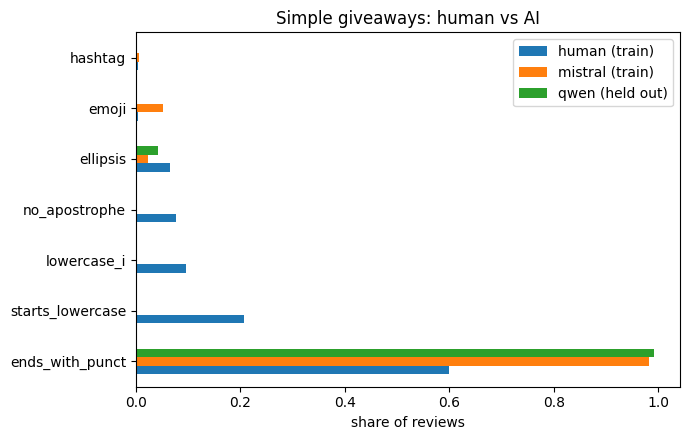

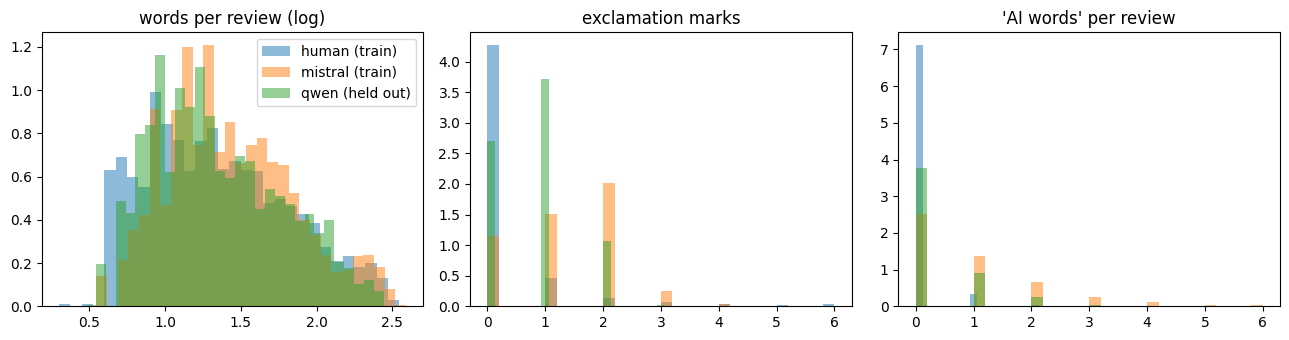

In [ ]:
show = ["ends_with_punct", "starts_lowercase", "lowercase_i", "no_apostrophe", "ellipsis", "emoji", "hashtag"]
ax = compare.loc[show].plot.barh(figsize=(7, 4.5))
ax.set(xlabel="share of reviews", title="Simple giveaways: human vs AI")
plt.tight_layout(); plt.savefig(RESULTS / "giveaways.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(axes, ["words", "exclamations", "ai_words"],
                          ["words per review (log)", "exclamation marks", "'AI words' per review"]):
    for name, g in groups.items():
        vals = np.log10(g[col] + 1) if col == "words" else g[col].clip(upper=6)
        ax.hist(vals, bins=30, alpha=0.5, density=True, label=name)
    ax.set_title(title)
axes[0].legend(); plt.tight_layout(); plt.savefig(RESULTS / "feature_histograms.png", dpi=120); plt.show()

## 3. The most distinctive words

For every word: how much more often it appears in AI reviews than in human ones (train split), as a log ratio with
add-one smoothing. Only words that appear at least 30 times in total.

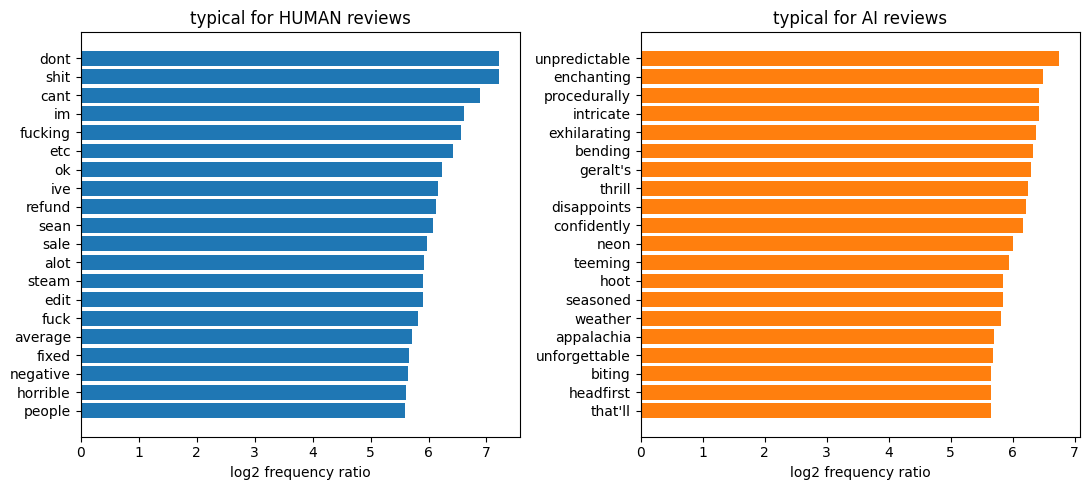

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

train = df[df.split == "train"]
cv = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-z][a-z']+\b", min_df=5)
X = cv.fit_transform(train.text)
counts_ai = np.asarray(X[train.label.values == 1].sum(axis=0)).ravel()
counts_h = np.asarray(X[train.label.values == 0].sum(axis=0)).ravel()
vocab = np.array(cv.get_feature_names_out())
keep = (counts_ai + counts_h) >= 30
log_ratio = np.log2((counts_ai + 1) / counts_ai.sum()) - np.log2((counts_h + 1) / counts_h.sum())
words = pd.DataFrame({"word": vocab, "ai": counts_ai, "human": counts_h, "log2_ratio": log_ratio})[keep]
top_ai = words.nlargest(20, "log2_ratio"); top_h = words.nsmallest(20, "log2_ratio")
pd.concat([top_ai.assign(side="AI"), top_h.assign(side="human")]).to_csv(RESULTS / "distinctive_words.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_h.word[::-1], -top_h.log2_ratio[::-1], color="tab:blue"); axes[0].set_title("typical for HUMAN reviews")
axes[1].barh(top_ai.word[::-1], top_ai.log2_ratio[::-1], color="tab:orange"); axes[1].set_title("typical for AI reviews")
for ax in axes: ax.set_xlabel("log2 frequency ratio")
plt.tight_layout(); plt.savefig(RESULTS / "distinctive_words.png", dpi=120); plt.show()

## 4. Baselines

All models are trained on `train` only. `val` is for choosing settings; `test` is the final comparison;
`heldout_qwen` tests an LLM never seen in training; `reserve_human` contains only real players, so every "AI"
prediction there is a **false positive** (a real reviewer accused of being a bot).

| Baseline | What it sees |
| --- | --- |
| Dummy | nothing (always the same class): the floor, 50% on balanced data |
| Length only | the word count |
| Simple features | the 15 features from section 2 |
| TF-IDF + logistic regression | the words and word pairs (classic text classifier) |

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

splits = {s: df[df.split == s] for s in ["train", "val", "test", "heldout_qwen", "reserve_human"]}

def evaluate(name, predict_proba, threshold=0.5):
    """Scores one model on every split. predict_proba: DataFrame -> probability of AI."""
    rows = []
    for s in ["val", "test", "heldout_qwen", "reserve_human"]:
        d = splits[s]; p = predict_proba(d); pred = (p >= threshold).astype(int)
        row = {"model": name, "split": s, "n": len(d)}
        if s == "reserve_human":   # only humans: the share flagged as AI is the false-positive rate
            row["false_positive_rate"] = pred.mean()
        else:
            row.update(accuracy=accuracy_score(d.label, pred), precision_ai=precision_score(d.label, pred, zero_division=0),
                       recall_ai=recall_score(d.label, pred), f1_ai=f1_score(d.label, pred),
                       roc_auc=roc_auc_score(d.label, p) if len(set(p)) > 1 else 0.5,
                       false_positive_rate=pred[d.label.values == 0].mean())
        rows.append(row)
    return rows

results, models = [], {}
y_train = splits["train"].label

# Dummy: always predicts the most frequent class (here a tie -> always "human")
dummy = DummyClassifier(strategy="most_frequent").fit(splits["train"][["words"]], y_train)
results += evaluate("dummy", lambda d: dummy.predict_proba(d[["words"]])[:, 1])

# Length only: logistic regression on log(word count)
length = make_pipeline(StandardScaler(), LogisticRegression()).fit(np.log1p(splits["train"][["words"]]), y_train)
results += evaluate("length only", lambda d: length.predict_proba(np.log1p(d[["words"]]))[:, 1])

# Simple features
simple = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(splits["train"][FEATURES].astype(float), y_train)
results += evaluate("simple features", lambda d: simple.predict_proba(d[FEATURES].astype(float))[:, 1])
models["simple features"] = simple

# TF-IDF of words and word pairs + logistic regression. lowercase=False keeps capitalisation as a signal;
# the token pattern keeps punctuation marks as tokens, so "!" or "..." can be learned too.
tfidf = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, lowercase=False,
                    token_pattern=r"[A-Za-z']+|[!?.,…#]+"),
    LogisticRegression(C=4, max_iter=2000))
tfidf.fit(splits["train"].text, y_train)
results += evaluate("TF-IDF + logistic regression", lambda d: tfidf.predict_proba(d.text)[:, 1])
models["tfidf"] = tfidf

metrics = pd.DataFrame(results)
metrics.round(3).to_csv(RESULTS / "metrics.csv", index=False)
metrics.pivot(index="model", columns="split", values="accuracy").drop(columns="reserve_human").round(3)

split,heldout_qwen,test,val
model,,,
TF-IDF + logistic regression,0.828,0.990,0.990
dummy,0.500,0.500,0.500
length only,0.478,0.530,0.528
simple features,0.813,0.916,0.905


**False-positive rate**: share of real human reviews labelled as AI (on the human-only reserve and on the human half of each split).

In [ ]:
metrics.pivot(index="model", columns="split", values="false_positive_rate").round(3)

split,heldout_qwen,reserve_human,test,val
model,,,,
TF-IDF + logistic regression,0.015,0.011,0.011,0.014
dummy,0.000,0.000,0.000,0.000
length only,0.449,0.446,0.437,0.460
simple features,0.086,0.119,0.084,0.096


### Which simple features does the model rely on?

Coefficients of the simple-features model (features are standardised, so the sizes are comparable).
Positive = pushes towards AI.

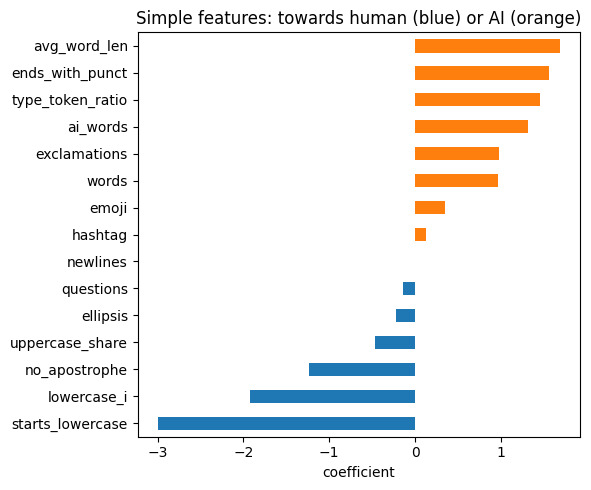

In [ ]:
coef = pd.Series(models["simple features"][-1].coef_[0], index=FEATURES).sort_values()
coef.round(2).to_csv(RESULTS / "simple_features_coefficients.csv")
ax = coef.plot.barh(figsize=(6, 5), color=["tab:blue" if v < 0 else "tab:orange" for v in coef])
ax.set(title="Simple features: towards human (blue) or AI (orange)", xlabel="coefficient")
plt.tight_layout(); plt.savefig(RESULTS / "simple_features_coefficients.png", dpi=120); plt.show()

### Results by length

Does the TF-IDF model only work on long reviews? Accuracy per word-count bucket on `test` and `heldout_qwen`.

In [ ]:
bins = [0, 5, 10, 20, 50, 100, 1000]
rows = []
for s in ["test", "heldout_qwen"]:
    d = splits[s].copy()
    d["pred"] = (tfidf.predict_proba(d.text)[:, 1] >= 0.5).astype(int)
    d["bucket"] = pd.cut(d.target_words, bins)   # bucket by the PAIR's target length, so both twins share it
    for b, g in d.groupby("bucket", observed=True):
        rows.append({"split": s, "length": f"{b.left + 1}-{b.right} words", "order": b.left, "n": len(g),
                     "accuracy": (g.pred == g.label).mean()})
by_len = pd.DataFrame(rows).sort_values("order").drop(columns="order")
by_len.round(3).to_csv(RESULTS / "tfidf_accuracy_by_length.csv", index=False)
by_len.pivot_table(index="length", columns="split", values="accuracy", sort=False).round(3)

split,test,heldout_qwen
length,,
1-5 words,0.975,0.744
6-10 words,0.984,0.785
11-20 words,0.993,0.831
21-50 words,0.992,0.868
51-100 words,0.997,0.892
101-1000 words,1.000,0.816


### A few mistakes of the TF-IDF model (test)

For the error analysis: the most confident wrong predictions. Short quotes only, for the report.

In [ ]:
d = splits["test"].copy()
d["p_ai"] = tfidf.predict_proba(d.text)[:, 1]
wrong = d[(d.p_ai >= 0.5) != (d.label == 1)].copy()
wrong["confidence"] = (wrong.p_ai - 0.5).abs()
for label, title in [(0, "HUMAN reviews predicted as AI"), (1, "AI reviews predicted as human")]:
    print(f"=== {title} ({(wrong.label == label).sum()} of {(d.label == label).sum()}) ===")
    for r in wrong[wrong.label == label].nlargest(6, "confidence").itertuples():
        print(f"p(AI)={r.p_ai:.2f} | {r.game} | {r.words} words | {r.text[:200]!r}")
    print()

=== HUMAN reviews predicted as AI (15 of 1327) ===
p(AI)=1.00 | Terraria | 10 words | 'Moo moo, moo moo moo moo moo moo. Moo moo!'
p(AI)=0.93 | PUBG: Battlegrounds | 27 words | 'Musuhnya sangat jago sekali, tidak ada tempat untuk player yang baru belajar bermain PUBG PC. Mau itu rank atau classic, keduanya sama saja tidak ada yang berbeda.'
p(AI)=0.91 | Terraria | 6 words | 'New Patch! Wow! WOw! Great Game!'
p(AI)=0.76 | Hades | 17 words | 'Absolutely love this game. The art style, the characters, the voice acting, the gameplay, everything is brilliant!'
p(AI)=0.72 | Sid Meier's Civilization VI | 5 words | 'Crashes every 10 minute. Unplayable'
p(AI)=0.70 | Slay the Spire | 43 words | 'Far FAR too addictive. A fantastic take on deck building games. High levels of replay, customization, strategy, and just pure enjoyment. Highly recommended for both casual card gamers and vets looking'

=== AI reviews predicted as human (12 of 1327) ===
p(AI)=0.12 | Cyberpunk 2077 | 9 words | "Blown away 

## 4b. Visuals for the report

1. The dataset: how big each split is and how the games are spread
2. Baselines side by side: Mistral test vs unseen Qwen vs false positives
3. Confusion matrices of the TF-IDF model
4. Where the TF-IDF model is unsure: p(AI) for human, Mistral and Qwen reviews
5. Accuracy by review length

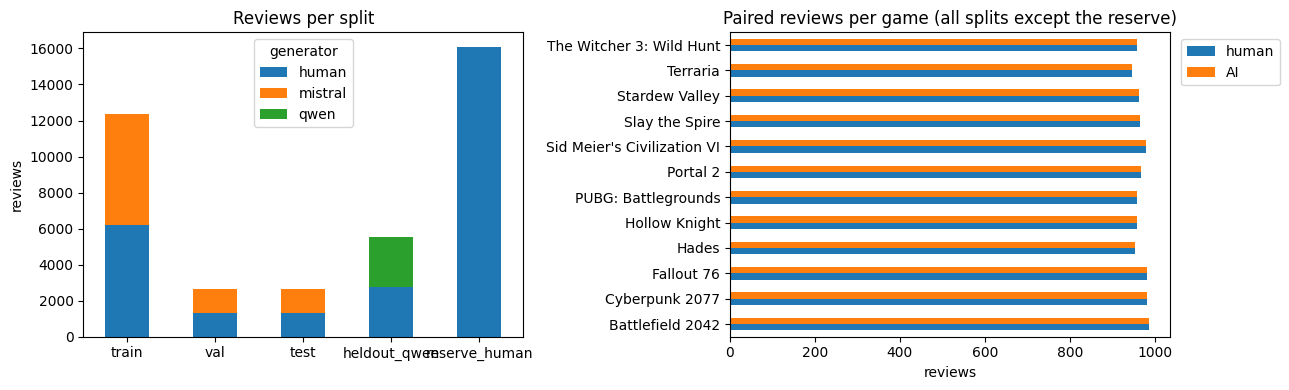

In [ ]:
# 1. Dataset overview
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sizes = df.groupby(["split", "generator"]).size().unstack(fill_value=0)
sizes = sizes.loc[["train", "val", "test", "heldout_qwen", "reserve_human"], ["human", "mistral", "qwen"]]
sizes.plot.bar(stacked=True, ax=axes[0], color=["tab:blue", "tab:orange", "tab:green"], rot=0)
axes[0].set(title="Reviews per split", ylabel="reviews", xlabel="")
paired = df[df.split != "reserve_human"]
per_game = paired.groupby(["game", "label"]).size().unstack().rename(columns={0: "human", 1: "AI"})
per_game.plot.barh(ax=axes[1], color=["tab:blue", "tab:orange"])
axes[1].set(title="Paired reviews per game (all splits except the reserve)", xlabel="reviews", ylabel="")
axes[1].legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig(RESULTS / "dataset_overview.png", dpi=120); plt.show()

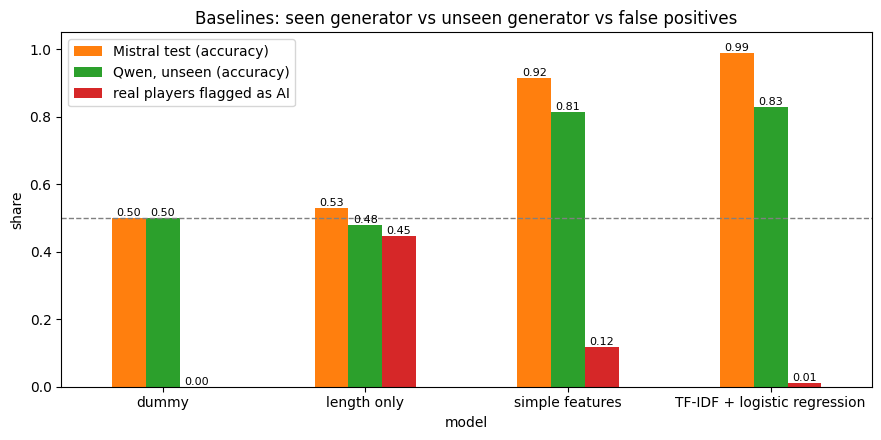

In [ ]:
# 2. Baselines side by side
acc = metrics.pivot(index="model", columns="split", values="accuracy")
fpr = metrics[metrics.split == "reserve_human"].set_index("model").false_positive_rate
order = ["dummy", "length only", "simple features", "TF-IDF + logistic regression"]
plot = pd.DataFrame({"Mistral test (accuracy)": acc.test, "Qwen, unseen (accuracy)": acc.heldout_qwen,
                     "real players flagged as AI": fpr}).loc[order]
ax = plot.plot.bar(figsize=(9, 4.5), rot=0, color=["tab:orange", "tab:green", "tab:red"])
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.set(ylim=(0, 1.05), ylabel="share", title="Baselines: seen generator vs unseen generator vs false positives")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "baselines_comparison.png", dpi=120); plt.show()

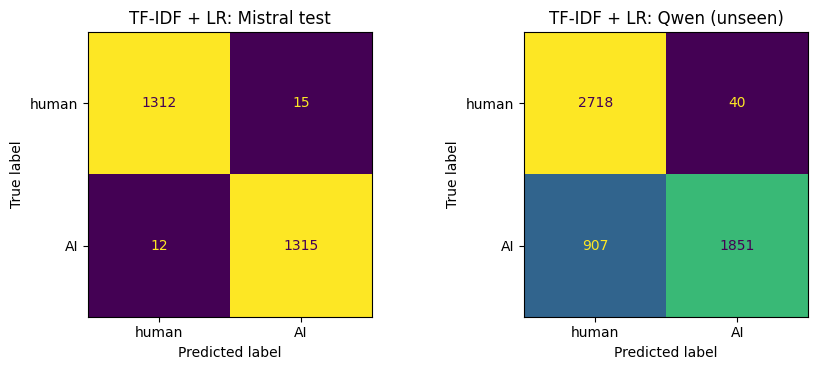

In [ ]:
# 3. Confusion matrices of the TF-IDF model
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, s, title in zip(axes, ["test", "heldout_qwen"], ["Mistral test", "Qwen (unseen)"]):
    d = splits[s]
    ConfusionMatrixDisplay(confusion_matrix(d.label, (tfidf.predict_proba(d.text)[:, 1] >= 0.5).astype(int)),
                           display_labels=["human", "AI"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"TF-IDF + LR: {title}")
plt.tight_layout(); plt.savefig(RESULTS / "tfidf_confusion.png", dpi=120); plt.show()

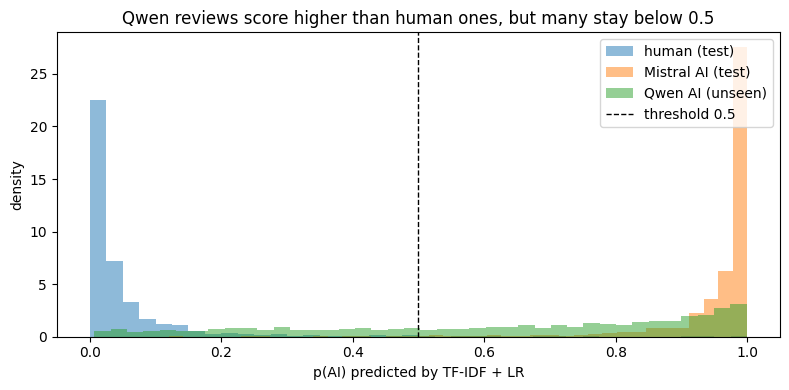

{'human (test)': '1.1% predicted AI', 'Mistral AI (test)': '99.1% predicted AI', 'Qwen AI (unseen)': '67.1% predicted AI'}


In [ ]:
# 4. p(AI) distributions: why Qwen is missed although ROC-AUC is high
p_groups = {
    "human (test)": tfidf.predict_proba(splits["test"][splits["test"].label == 0].text)[:, 1],
    "Mistral AI (test)": tfidf.predict_proba(splits["test"][splits["test"].label == 1].text)[:, 1],
    "Qwen AI (unseen)": tfidf.predict_proba(splits["heldout_qwen"][splits["heldout_qwen"].label == 1].text)[:, 1],
}
plt.figure(figsize=(8, 4))
for (name, p), color in zip(p_groups.items(), ["tab:blue", "tab:orange", "tab:green"]):
    plt.hist(p, bins=40, alpha=0.5, density=True, label=name, color=color)
plt.axvline(0.5, color="black", ls="--", lw=1, label="threshold 0.5")
plt.xlabel("p(AI) predicted by TF-IDF + LR"); plt.ylabel("density"); plt.legend()
plt.title("Qwen reviews score higher than human ones, but many stay below 0.5")
plt.tight_layout(); plt.savefig(RESULTS / "tfidf_probability_histogram.png", dpi=120); plt.show()
print({k: f"{(v >= 0.5).mean():.1%} predicted AI" for k, v in p_groups.items()})

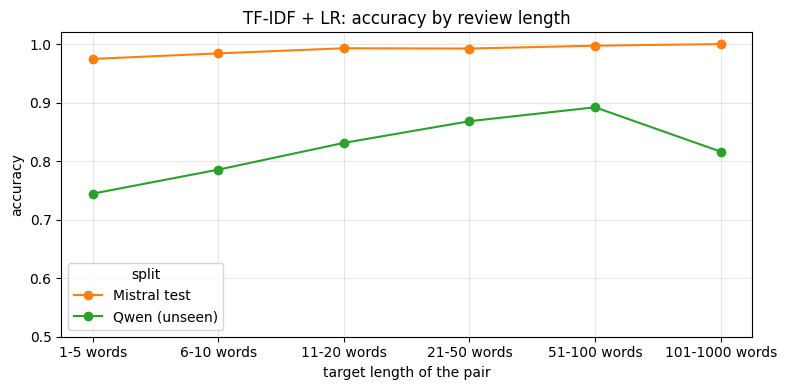

In [ ]:
# 5. Accuracy by review length
pivot = by_len.pivot_table(index="length", columns="split", values="accuracy", sort=False)
pivot = pivot.rename(columns={"test": "Mistral test", "heldout_qwen": "Qwen (unseen)"})
ax = pivot.plot(marker="o", figsize=(8, 4), color=["tab:orange", "tab:green"])
ax.set(ylim=(0.5, 1.02), ylabel="accuracy", xlabel="target length of the pair",
       title="TF-IDF + LR: accuracy by review length")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS / "tfidf_accuracy_by_length.png", dpi=120); plt.show()

## 5. Takeaways for the next notebooks

Written after the first run (22 Nov); numbers from `results/03_baselines/metrics.csv`.

- **The length fix worked:** length alone gives 53% on `test` (dummy 50%). Length is no longer a giveaway.
- **Human "sloppiness" is the strongest simple signal, and the models never imitate it.** Humans start with a lowercase
  letter in 21% of reviews, write a lowercase "i" in 10% and skip apostrophes ("dont", "im") in 8%. Mistral and Qwen:
  **0% for all three**. AI reviews end with punctuation in 98–99% of cases, human ones in 60%.
- **AI vocabulary:** "AI words" (immersive, captivating, masterpiece…) appear 0.87× per Mistral review vs 0.06× per human
  one. The most AI-typical words are adjectives like *unpredictable, enchanting, intricate, exhilarating, teeming*; the
  most human ones are *dont, shit, cant, im, refund, sale, steam, edit, fixed*: informal writing and the Steam context
  (refunds, sales, edits after patches) that a model prompted with only the game name does not know.
- **15 simple features already reach 91.6%** on `test`; **TF-IDF + logistic regression 99.0%** (false positives on real
  players: 1.1%). Detecting the generator seen in training is easy.
- **The real challenge is the unseen generator:** on Qwen the TF-IDF model drops to **82.8%**: precision stays 98% but it
  finds only **67% of Qwen reviews** (recall). ROC-AUC is still 0.97, so Qwen reviews still score higher than human ones,
  but below the 0.5 threshold tuned on Mistral. Short Qwen reviews are hardest (74% on 1–5 words).
- **Errors on `test`** (27 of 2,654) are mostly short or unusual reviews: a human writing only "Moo moo, moo moo…", an
  Indonesian review that passed the language check, enthusiastic human praise in perfect English; AI reviews that
  sound casual ("Fun, but needs fixes.", "Terrible balance patch ruined the game. :(").

**Question for the neural models (notebook 04):** not "can they beat 99% on Mistral" (hardly possible), but **do they
generalise better to Qwen**, and at what false-positive cost?